# EDA — υποσύνολο του ESCI ανά κατηγορία (case study)

Το ESCI καλύπτει **όλες** τις κατηγορίες προϊόντων, αλλά δεν έχει στήλη κατηγορίας.
Για να μελετήσουμε μία κατηγορία ξεχωριστά, αντιστοιχίζουμε τα products του ESCI με
το metadata της κατηγορίας στο Amazon Reviews 2023 (McAuley Lab):

```
ESCI product_id (ASIN)  ──join──  meta_<Category> parent_asin
```

Ένα product ανήκει στην κατηγορία αν το ASIN του υπάρχει στο meta_<Category>.
Αλλάζοντας τη μεταβλητή `CATEGORY` παρακάτω, το notebook τρέχει για άλλη κατηγορία
(πρέπει πρώτα να κατέβει: `python -m src.meta --category <Category>`).

Όλοι οι υπολογισμοί γίνονται από το `src/category_subset.py`
(`python -m src.category_subset --category <Category>` γράφει τα ίδια στο
`results/eda/categories/<category>/`).

**Προαπαιτούμενα:** `python -m src.data` (splits) και `python -m src.meta` (meta parquet).

In [1]:
CATEGORY = "Electronics"   # κατηγορία του Amazon Reviews 2023

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import category_subset as cs
from src.data import load_config
from src.eda import style

pd.set_option("display.max_colwidth", 90)
cfg = load_config("configs/data.yaml")
OUT = ROOT / "results/eda/categories" / cs.slug(CATEGORY)
OUT.mkdir(parents=True, exist_ok=True)
style()

## 1. Τα δύο datasets

In [3]:
esci, meta = cs.load(cfg, CATEGORY)
print("ESCI small-us:", esci.shape, "| queries:", esci["query_id"].nunique(), "| products:", esci["product_id"].nunique())
print(f"meta_{CATEGORY}:", meta.shape)
meta.head()

ESCI small-us: (601354, 7) | queries: 29844 | products: 482105
meta_Electronics: (1610012, 8)


,parent_asin,meta_title,main_category,categories,store,price,average_rating,rating_number
0,B00MCW7G9M,FS-1051 FATSHARK TELEPORTER V3 HEADSET,All Electronics,Electronics > Television & Video > Video Glasses,Fat Shark,NaN,3.5,6
1,B00YT6XQSE,Ce-H22B12-S1 4Kx2K Hdmi 4Port,All Electronics,Electronics > Television & Video > Accessories > Cables > HDMI Cables,SIIG,NaN,5.0,1
2,B07SM135LS,Digi-Tatoo Decal Skin Compatible With MacBook Pro 13 inch (Model A2338/ A2289/ A2251) ...,Computers,Electronics > Computers & Accessories > Laptop Accessories > Skins & Decals > Decals,Digi-Tatoo,19.99,4.5,246
3,B089CNGZCW,NotoCity Compatible with Vivoactive 4 band 22mm Quick Release Silicone Bands/Garmin Da...,AMAZON FASHION,"Electronics > Wearable Technology > Clips, Arm & Wristbands",NotoCity,9.99,4.5,233
4,B004E2Z88O,Motorola Droid X Essentials Combo Pack,Cell Phones & Accessories,Electronics > Computers & Accessories > Computer Accessories & Peripherals > Memory Ca...,Verizon,14.99,3.8,64


## 2. Coverage του join

Πόσα ESCI products βρίσκονται στο meta της κατηγορίας, και πόσα queries «περνούν»
με διάφορους ορισμούς του «query της κατηγορίας».

In [4]:
m, per_q, cov = cs.coverage(esci, meta)
display(pd.Series({k: v for k, v in cov.items() if not isinstance(v, dict)}))
display(pd.DataFrame(cov["queries_by_threshold"]).T)

meta_products             1.610012e+06
esci_products             4.821050e+05
products_matched          1.196600e+04
products_matched_share    2.480000e-02
rows_matched_share        2.700000e-02
queries                   2.984400e+04
dtype: float64

,total,train,val,test
>=1 product,3537,2243,234,1060
>=50% products,636,377,38,221
>=50% of E products,856,523,54,279
all products,0,0,0,0


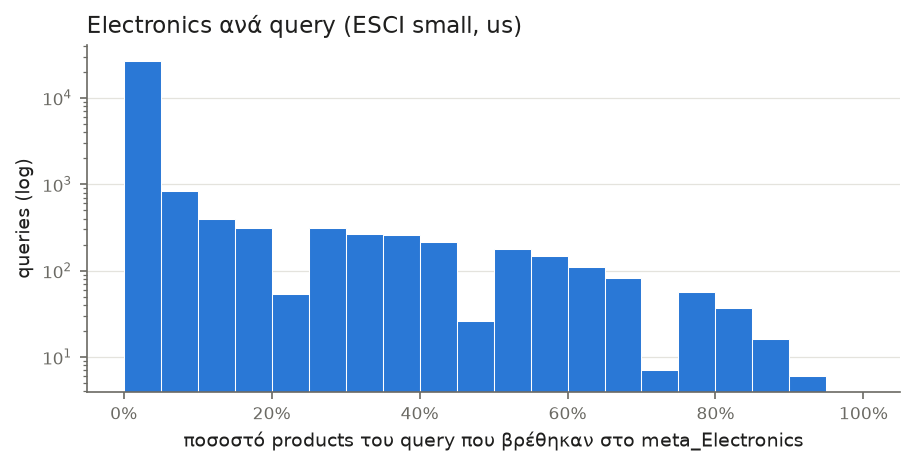

In [5]:
cs.fig_frac(per_q, CATEGORY, OUT)
display(Image(OUT / "fraction_per_query.png"))

## 3. Sanity check: πόσα προϊόντα της κατηγορίας χάνει το join;

Παίρνουμε queries που **αναμφίβολα** ανήκουν στην κατηγορία (λέξεις-κλειδιά, ορισμένες στο
`KEYWORDS` του `src/category_subset.py`) και μετράμε τι ποσοστό των products τους βρίσκει
το join. Αν το join δούλευε τέλεια, τα E products αυτών των queries θα έβγαιναν σχεδόν όλα μέσα.

In [6]:
kw, kw_missed = cs.keyword_check(m, CATEGORY)
if kw is None:
    print(f"Δεν έχουν οριστεί λέξεις-κλειδιά για {CATEGORY} — το sanity check παραλείπεται.")
else:
    print("queries με λέξη-κλειδί:", kw["queries"])
    display(pd.Series(kw["matched_share_by_label"], name="matched share"))
    print("Δείγμα E products που ΔΕΝ βρέθηκαν στο meta:")
    display(kw_missed.head(15))

queries με λέξη-κλειδί: 756


E    0.2971
S    0.3021
C    0.2912
I    0.2200
Name: matched share, dtype: float64

Δείγμα E products που ΔΕΝ βρέθηκαν στο meta:


,query,product_id,product_title
258341,pair of bluetooth headphones for tv,B07QWY6KN2,Wireless TV Headphones - Pohopa W239 2.4GHz Over Ear Stereo Headphone 2 Packs for TV W...
470399,converter ethernet to hdmi,B081NJ18RM,"HDMI Extender,HDMI to RJ45 Network Cable Extender Converter Repeater Over Cat 5e /6 /6..."
524575,macbook pro 15 inch keyboard cover candy colir,B016KM7SKG,"Allinside Pink Ombre Keyboard Cover Skin for MacBook Pro 13"" 15"" 17"" (2015 or Older Ve..."
496467,go pro camera,B07GDFTSPV,GoPro Hero7 White — Waterproof Action Camera with Touch Screen 1080p HD Video 10MP Photos
45519,alienware monitor 34,B07K7TW1JD,"Dell Alienware AW3418DW 34"" 21:9 Curved 120 Hz G-Sync IPS Gaming Monitor with HDMI Cable"
289699,roc tv show,B074JG5T9J,See Dick Continue to Run
231432,microtouch solo razor as seen on tv,B07TS32WF8,OneBlade Face + Advanced Hybrid Electric Trimmer and Shaver Rechargeable Razor for Men
50544,apple headphones,B083ZH8JH7,"Earbuds, 3.5mm Wired Microphone Earphones Stereo Headphones Noise Isolating Headset Co..."
177820,hp keyboard protector,B076KD7PVZ,"CaseBuy Keyboard Cover Compatible for 2020 2019 2018 HP 14"" Laptop / HP Pavilion X360 ..."
348300,usb multi adapter,B07L32B9C2,"Anker 4-Port USB 3.0 Hub, Ultra-Slim Data USB Hub with 2 ft Extended Cable [Charging N..."


**Εύρημα (Electronics):** μόνο ~30% των E products σε προφανώς-electronics queries βρίσκονται
στο meta_Electronics — ενώ στη λίστα που λείπουν υπάρχουν καθαρά electronics (SSD, routers, TV).
Το join μέσω ASIN έχει **υψηλή ακρίβεια αλλά χαμηλή κάλυψη (recall)**.

Πιθανές αιτίες (δεν έχουν επαληθευτεί ακόμα):
- το ESCI έχει ASIN *παραλλαγών* (child), ενώ το Amazon 2023 κρατά μόνο `parent_asin`·
- προϊόντα του ESCI (2020–21) που δεν υπάρχουν στο dataset του 2023·
- προϊόντα σε άλλη κατηγορία του Amazon 2023 (π.χ. Cell Phones & Accessories).

Άρα το υποσύνολο παρακάτω είναι **προκαταρκτικό**: ό,τι περιέχει ανήκει στην κατηγορία, αλλά λείπουν πολλά.

## 4. EDA στο υποσύνολο

Ορισμός: ένα query ανήκει στο υποσύνολο αν **≥50% των E products** του βρίσκονται στο meta
της κατηγορίας (το E είναι αυτό που ζητούσε ο χρήστης, άρα δείχνει την πρόθεση του query).

In [7]:
sub, sub_q, words, eda_out = cs.subset_eda(m, per_q, CATEGORY)
display(pd.Series({k: eda_out[k] for k in ["category", "definition", "queries", "rows", "matched_products"]}))
display(pd.DataFrame({k: eda_out[k] for k in
        ["label_dist", "queries_with_C", "candidates_per_query_median", "query_words_median"]}))

category                    Electronics
definition          >=50% of E products
queries                             856
rows                              14268
matched_products                   6008
dtype: object

,label_dist,queries_with_C,candidates_per_query_median,query_words_median
all_small_us,"{'E': 0.4349, 'S': 0.3512, 'C': 0.0452, 'I': 0.1687}",0.2581,16.0,4.0
electronics,"{'E': 0.3668, 'S': 0.4264, 'C': 0.0853, 'I': 0.1215}",0.3855,16.0,4.0


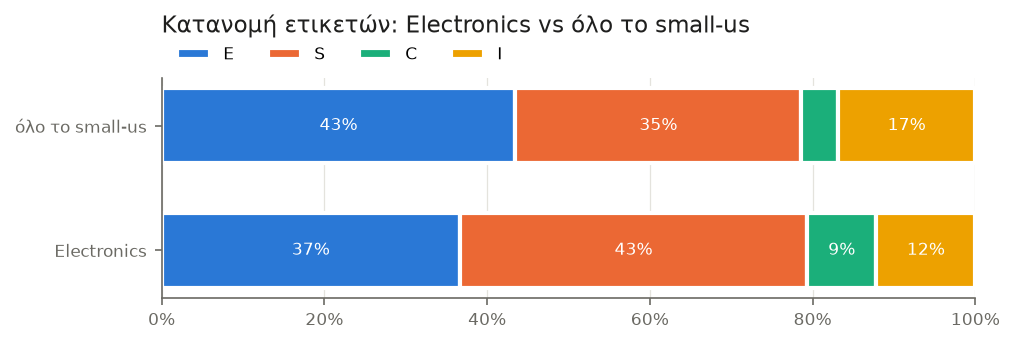

In [8]:
cs.fig_label_compare(eda_out, OUT)
display(Image(OUT / "labels_subset_vs_all.png"))

Στα electronics υπάρχουν περισσότερα **S** και **C** (αξεσουάρ, συμβατά προϊόντα) και λιγότερα I.

,all_small_us,electronics
other,0.8078,0.8540
parse_pattern,0.0857,0.0444
negations,0.0777,0.0713
behavioral,0.0255,0.0058
nlqec,0.0033,0.0245


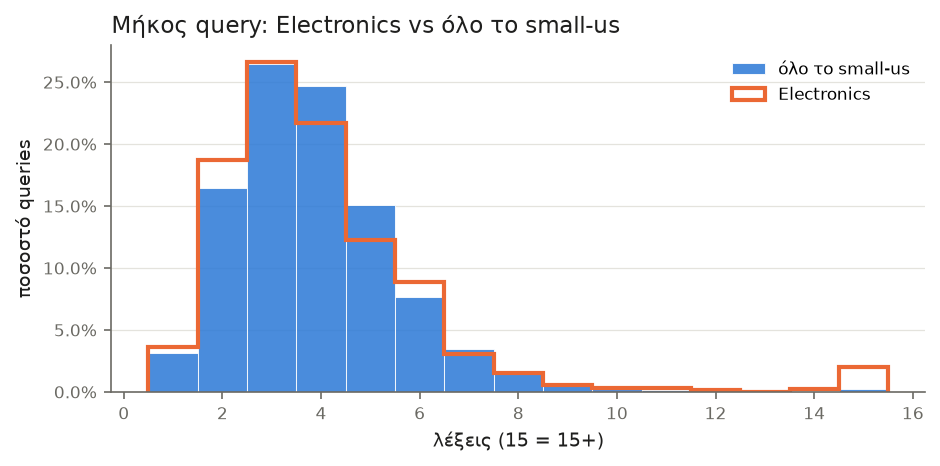

In [9]:
display(pd.DataFrame(eda_out["source_dist"]).fillna(0))
cs.fig_query_length(words, sub_q, CATEGORY, OUT)
display(Image(OUT / "query_length.png"))

### Υποκατηγορίες, τιμές και βαθμολογίες (από το meta της κατηγορίας)

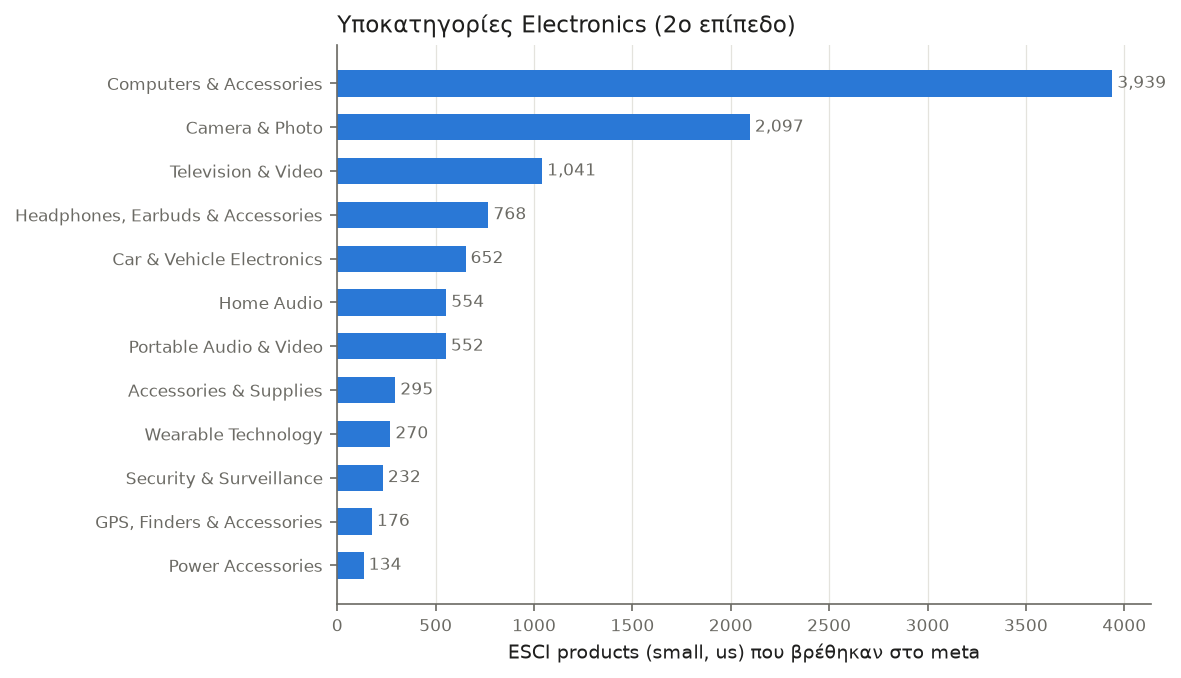

All Electronics              3583
Computers                    2821
Camera & Photo               1797
Cell Phones & Accessories    1159
Home Audio & Theater          553
Industrial & Scientific       278
Amazon Devices                177
Car Electronics               159
Automotive                    147
Office Products               137
Apple Products                136
Sports & Outdoors             134
Tools & Home Improvement      133
Amazon Home                    89
AMAZON FASHION                 87
Name: products, dtype: int64

In [10]:
cs.fig_categories(eda_out, OUT)
display(Image(OUT / "subcategories.png"))
pd.Series(eda_out["top_main_category"], name="products")

available_share        0.5659
count               3400.0000
mean                 220.0800
std                  634.8100
min                    3.0800
25%                   19.7700
50%                   60.9400
75%                  199.9500
95%                  901.1800
max                23390.1200
Name: price ($), dtype: float64

count    6008.00
mean        4.26
std         0.41
min         1.00
25%         4.10
50%         4.30
75%         4.50
max         5.00
Name: average_rating, dtype: float64

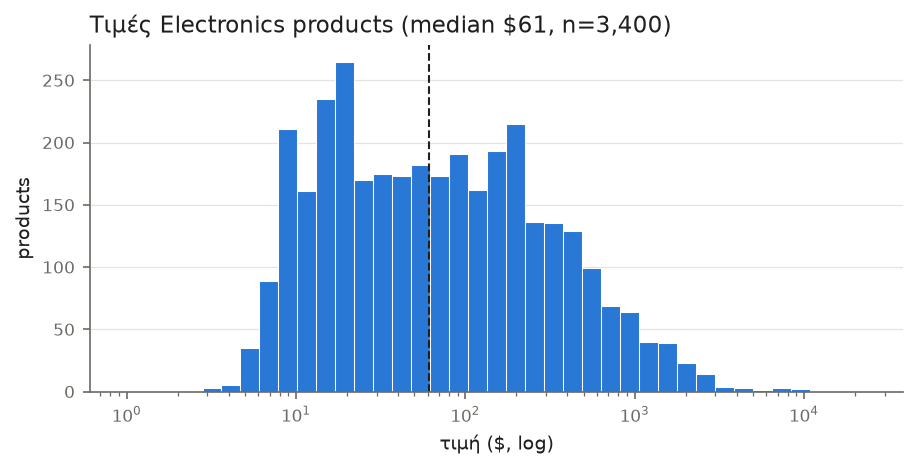

In [11]:
display(pd.Series(eda_out["price"], name="price ($)"))
display(pd.Series(eda_out["average_rating"], name="average_rating"))
cs.fig_price(sub, CATEGORY, OUT)
display(Image(OUT / "price.png"))

### Δείγμα queries του υποσυνόλου (για χειροκίνητο έλεγχο)

In [12]:
qtext = m.drop_duplicates("query_id").set_index("query_id")["query"]
qtext.loc[sub_q].sample(min(20, len(sub_q)), random_state=42)

query_id
90536                                     sanus blt2-b1
77173                                           padmate
6973                        adult stickers for men bomb
17149                               blink home security
44911                 genuine cowhide ipad pro 11 folio
105897       tv boxes and modems compatble with comcast
90337                         samsung tv wall mount kit
24121           cd player alarm clock radio for bedroom
90340                              samsung video camera
109032                                     vivofit is 4
73747                            nikon monarch hg 10x30
36605                                        echo input
80457                                     pioneer radio
43723                                 fx keyboard mouse
96118                                     sony fm radio
14373                                  beats by dre pro
53849                    ipad for a 6th generation 32gb
53917     ipad pro 12.9 screen protecto

## 5. Συμπεράσματα (Electronics)

1. Το join μέσω ASIN βρίσκει μόνο μικρό μέρος του ESCI και, σε προφανώς-electronics
   queries, χάνει ~70% των products → **το υποσύνολο είναι μικρό και ελλιπές**.
2. Με τον ορισμό «≥50% των E» προκύπτουν λίγες εκατοντάδες queries — λίγα για εκπαίδευση,
   αρκετά ως **ξεχωριστό test set** (case study) για μοντέλα εκπαιδευμένα σε όλο το ESCI.
3. Τα electronics queries διαφέρουν: περισσότερα S και C (αξεσουάρ/συμβατότητα), λιγότερα I.
4. Τα meta δίνουν πληροφορία που λείπει από το ESCI (κατηγορίες, τιμή για ~57% των products,
   βαθμολογίες) — χρήσιμη για το RAG.

**Ανοιχτό:** βελτίωση του join (child→parent ASIN από τα reviews, ή classifier σε title)
και επιλογή άλλων κατηγοριών για σύγκριση.